# Tempo di elaborazione della sequenza: analisi finale

**Non richiede un nuovo benchmark.** Usa `wall_seconds` dei cinque run energetici per sequenza e metodo, non il tempo dei replay che scrivono i CSV di accuracy.

La misura comprende l'intero comando: caricamento dati e modello, startup, elaborazione, shutdown, comunicazione e attese interne. Esclude i cooldown esterni del runner. Non e' una misura del solo forward neurale o della latenza del singolo evento.

La final analysis usa lo stesso controllo di validita' temporale delle figure accuracy/energy: DHP19 D09 e D10 sono esclusi da tutti gli aggregati finali. I run originali non vengono modificati e non viene rilanciato alcun benchmark.


In [1]:
from pathlib import Path
import os
import sys
import json
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display

# Sessione realmente eseguita. Non contiene frequenze hard-coded nei grafici.
SESSION = "energy_accuracy_final_5hz_ofk"
# Di norma lasciare None: vengono verificati sia il mount /data sia HOME/data.
RESULTS_DIR = None

# Il notebook usa lo stesso modulo dello script, evitando due implementazioni diverse.
package_candidates = []
if os.environ.get("MOVEENET_FINAL_PACKAGE"):
    package_candidates.append(Path(os.environ["MOVEENET_FINAL_PACKAGE"]))
for parent in (Path.cwd(), *Path.cwd().parents):
    package_candidates.extend((parent, parent / "moveEnetFlow/experiments/ExpFinal"))
PACKAGE = next((p for p in package_candidates if (p / "final_analysis.py").is_file()), None)
if PACKAGE is None:
    raise RuntimeError("Aprire questo notebook dalla directory ExpFinal/notebooks nella repository in cui e' stato estratto il pacchetto.")
sys.path.insert(0, str(PACKAGE))
from final_analysis import plot_tradeoff, plot_tradeoff_all, plot_energy, plot_runtime

if RESULTS_DIR is None:
    candidates = []
    if os.environ.get("MOVEENET_FINAL_RESULTS"):
        candidates.append(Path(os.environ["MOVEENET_FINAL_RESULTS"]))
    candidates.extend((Path("/data/MoveEnet_OFK_results/Final") / SESSION,
                       Path.home() / "data/MoveEnet_OFK_results/Final" / SESSION))
    RESULTS_DIR = next((p for p in candidates if (p / "tables/energy_runtime_summary.csv").is_file()), None)
if RESULTS_DIR is None:
    raise RuntimeError("Prima eseguire finish_experiment.sh --prepare-only oppure il completamento --resume, dall'host. Nessun CSV accuracy manuale deve essere creato.")
RESULTS_DIR = Path(RESULTS_DIR).expanduser().resolve()
TABLES = RESULTS_DIR / "tables"
FIGURES = RESULTS_DIR / "figures"
completion = json.loads((RESULTS_DIR / "completion.json").read_text())
audit = json.loads((RESULTS_DIR / "audit_energy.json").read_text())
print("Directory risultati:", RESULTS_DIR)
print("Run energia OK unici:", audit["successful_unique_runs"])
print("Accuracy completate:", completion["accuracy_completed"], "/", completion["accuracy_required"])
for warning in audit.get("warnings", []):
    print("DA ESAMINARE:", warning)


Directory risultati: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk
Run energia OK unici: 420
Accuracy completate: 84 / 84
DA ESAMINARE: Runtime anomalo da esaminare: ('h36m', 'H04', 'yolo') tempi=[27.693281801, 28.448229428, 28.268494937, 161.912793747, 26.230995587]


## Final-analysis quality-control exclusion

For the final DHP19 aggregate, recordings **D09** and **D10** are excluded across **all methods and all reported metrics**.

The exclusion is based on the temporal-coverage diagnostic, not on accuracy: for these recordings the prediction timestamps extend substantially beyond the available ground-truth interval, producing many rows outside the GT span. The raw experimental outputs are left unchanged; only the final aggregation/plotting stage applies this common validity mask.

Consequently, the final figures use:
- eH36M: 12 sequences per method;
- DHP19: 10 valid sequences per method.

The experiment still acquired 420 energy runs in total. The final common-subset analysis omits the 30 runs belonging to D09/D10 (2 sequences x 3 DHP19 methods x 5 repetitions), so 390 energy runs contribute to the reported aggregates.


In [2]:
import numpy as np

# Final-analysis QC mask. Keep this centralized so every metric uses the same subset.
EXCLUDED_SAMPLES = {("dhp19", "D09"), ("dhp19", "D10")}
BOOTSTRAP_SEED = 20260911
BOOTSTRAP_REPLICATES = 5000
FINAL_FIGURE_SUFFIX = "_valid_subset"

def apply_sample_exclusions(df):
    out = df.copy()
    mask = pd.Series(False, index=out.index)
    for dataset, sample_id in EXCLUDED_SAMPLES:
        mask |= ((out["dataset"] == dataset) & (out["sample_id"] == sample_id))
    return out.loc[~mask].copy()

def expected_sequence_count(dataset):
    return 10 if dataset == "dhp19" else 12

def _ci95(values):
    lo, hi = np.quantile(values, [0.025, 0.975])
    return float(lo), float(hi)

def summarize_runtime_valid_subset(raw, base_summary):
    rows = []

    for _, base in base_summary.iterrows():
        dataset = base["dataset"]
        model = base["model"]
        g = raw[(raw["dataset"] == dataset) & (raw["model"] == model)].copy()
        g = g.sort_values("sample_id").reset_index(drop=True)

        expected = expected_sequence_count(dataset)
        n = g["sample_id"].nunique()
        if n != expected or len(g) != expected:
            raise RuntimeError(
                f"Subset finale inatteso per {dataset}/{model}: "
                f"{n} sample unici, {len(g)} righe; attesi {expected}."
            )

        E = pd.to_numeric(g["energy_j"], errors="raise").to_numpy(float)
        E_cpu = pd.to_numeric(g["cpu_energy_j"], errors="raise").to_numpy(float)
        E_gpu = pd.to_numeric(g["gpu_energy_j"], errors="raise").to_numpy(float)
        T = pd.to_numeric(g["sequence_wall_seconds"], errors="raise").to_numpy(float)
        D = pd.to_numeric(g["input_span_s"], errors="raise").to_numpy(float)

        rng = np.random.default_rng(BOOTSTRAP_SEED)
        ix = rng.integers(0, len(g), size=(BOOTSTRAP_REPLICATES, len(g)))

        boot_energy = E[ix].mean(axis=1)
        boot_wall = T[ix].mean(axis=1)
        boot_rtf = T[ix].sum(axis=1) / D[ix].sum(axis=1)
        boot_normalized_energy = E[ix].sum(axis=1) / D[ix].sum(axis=1)

        energy_lo, energy_hi = _ci95(boot_energy)
        wall_lo, wall_hi = _ci95(boot_wall)
        rtf_lo, rtf_hi = _ci95(boot_rtf)
        norm_lo, norm_hi = _ci95(boot_normalized_energy)

        row = base.to_dict()
        row.update({
            "n_sequences": expected,
            "energy_mean_j": float(E.mean()),
            "energy_sequence_sd_j": float(E.std(ddof=1)),
            "cpu_energy_mean_j": float(E_cpu.mean()),
            "gpu_energy_mean_j": float(E_gpu.mean()),
            "wall_mean_s": float(T.mean()),
            "wall_sequence_sd_s": float(T.std(ddof=1)),
            "input_span_mean_s": float(D.mean()),
            # Ratio-of-sums, matching the original final-analysis convention.
            "real_time_factor": float(T.sum() / D.sum()),
            "speed_vs_realtime": float(D.sum() / T.sum()),
            "energy_j_per_input_second": float(E.sum() / D.sum()),
            "combined_mean_power_w": float(E.sum() / T.sum()),
            "cpu_mean_power_w": float(E_cpu.sum() / T.sum()),
            "gpu_mean_power_w": float(E_gpu.sum() / T.sum()),
            "amortized_ms_per_nominal_output_slot":
                float(1000.0 * T.sum() / (D.sum() * float(base["output_hz"]))),
            "energy_ci95_low": energy_lo,
            "energy_ci95_high": energy_hi,
            "wall_ci95_low": wall_lo,
            "wall_ci95_high": wall_hi,
            "rtf_ci95_low": rtf_lo,
            "rtf_ci95_high": rtf_hi,
            "normalized_energy_ci95_low": norm_lo,
            "normalized_energy_ci95_high": norm_hi,
        })
        rows.append(row)

    return pd.DataFrame(rows)[base_summary.columns]

def summarize_accuracy_valid_subset(paired, runtime_summary, base_accuracy_summary):
    rows = []

    for _, runtime_row in runtime_summary.iterrows():
        dataset = runtime_row["dataset"]
        model = runtime_row["model"]
        g = paired[(paired["dataset"] == dataset) & (paired["model"] == model)].copy()
        g = g.sort_values("sample_id").reset_index(drop=True)

        expected = expected_sequence_count(dataset)
        n = g["sample_id"].nunique()
        if n != expected or len(g) != expected:
            raise RuntimeError(
                f"Subset accuracy inatteso per {dataset}/{model}: "
                f"{n} sample unici, {len(g)} righe; attesi {expected}."
            )

        n_points = pd.to_numeric(g["n_points"], errors="raise").to_numpy(float)
        correct = pd.to_numeric(g["pck_0.2_correct_points"], errors="raise").to_numpy(float)
        sum_err = pd.to_numeric(g["sum_err_px"], errors="raise").to_numpy(float)

        rng = np.random.default_rng(BOOTSTRAP_SEED)
        ix = rng.integers(0, len(g), size=(BOOTSTRAP_REPLICATES, len(g)))

        boot_pck = 100.0 * correct[ix].sum(axis=1) / n_points[ix].sum(axis=1)
        boot_mpjpe = sum_err[ix].sum(axis=1) / n_points[ix].sum(axis=1)
        pck_lo, pck_hi = _ci95(boot_pck)
        mpjpe_lo, mpjpe_hi = _ci95(boot_mpjpe)

        row = runtime_row.to_dict()
        row.update({
            "pck_weighted_percent": float(100.0 * correct.sum() / n_points.sum()),
            "mpjpe_weighted_px": float(sum_err.sum() / n_points.sum()),
            "pck_sequence_macro_percent": float(pd.to_numeric(g["pck"], errors="raise").mean()),
            "mpjpe_sequence_macro_px": float(pd.to_numeric(g["mpjpe"], errors="raise").mean()),
            "total_evaluated_joint_points": int(n_points.sum()),
            "accuracy_aggregation": "point_weighted_as_ExpA",
            "min_observed_output_hz": float(g["observed_output_hz"].min()),
            "max_observed_output_hz": float(g["observed_output_hz"].max()),
            "pck_ci95_low": pck_lo,
            "pck_ci95_high": pck_hi,
            "mpjpe_ci95_low": mpjpe_lo,
            "mpjpe_ci95_high": mpjpe_hi,
        })
        rows.append(row)

    result = pd.DataFrame(rows)
    return result[base_accuracy_summary.columns]

print("QC exclusion attiva:", sorted(EXCLUDED_SAMPLES))


QC exclusion attiva: [('dhp19', 'D09'), ('dhp19', 'D10')]


## Quantita' misurate e derivate

Per la sequenza $s$, durata di input $D_s$ e media dei cinque tempi misurati $T_s$:

$$RTF_s = T_s/D_s,\qquad v_s=D_s/T_s.$$

Il rapporto inferiore a 1 indica elaborazione offline piu' veloce della durata del dato **in media**. Non dimostra che tutte le scadenze siano rispettate in streaming.

Il costo ammortizzato su slot nominali a frequenza $f$ e':

$$t_{slot}(f)=1000\,T_s/(D_s f)\quad\mathrm{ms/slot}.$$

Cambiare $f$ in questa divisione **non** simula l'esecuzione della rete a un'altra frequenza. In particolare per MoveEnetOFK il numeratore comprende rete, eventi, optical flow e Kalman. Non va etichettato come inference latency.

In [3]:
runtime_all = pd.read_csv(TABLES / "sequence_runtime_by_sample.csv")
energy_runtime_all = pd.read_csv(TABLES / "energy_runtime_by_sample.csv")
base_runtime_summary = pd.read_csv(TABLES / "energy_runtime_summary.csv")

runtime = apply_sample_exclusions(runtime_all)
energy_runtime = apply_sample_exclusions(energy_runtime_all)
summary_runtime = summarize_runtime_valid_subset(energy_runtime, base_runtime_summary)

runtime.to_csv(TABLES / "sequence_runtime_by_sample_valid_subset.csv", index=False)
summary_runtime.to_csv(TABLES / "energy_runtime_summary_valid_subset.csv", index=False)

display(summary_runtime[["dataset", "method", "net_hz", "n_sequences", "wall_mean_s",
                         "real_time_factor", "speed_vs_realtime",
                         "amortized_ms_per_nominal_output_slot"]])
display(runtime.head(7))


,dataset,method,net_hz,n_sequences,wall_mean_s,real_time_factor,speed_vs_realtime,amortized_ms_per_nominal_output_slot
0,dhp19,EventPointPose,200.0,10,29.527584,1.607916,0.621923,8.039578
1,dhp19,MoveEnetOFK,5.0,10,5.395871,0.293831,3.403323,1.469153
2,dhp19,MoveEnet only,200.0,10,25.594011,1.393714,0.717507,6.968570
3,h36m,MoveEnetOFK,5.0,12,11.129992,0.217272,4.602530,1.086359
4,h36m,MoveEnet only,50.0,12,26.411024,0.515577,1.939574,2.577886
5,h36m,OpenPose,50.0,12,177.899846,3.477210,0.287587,17.386049
6,h36m,YOLOPose,50.0,12,28.789206,0.562710,1.777113,2.813552


,dataset,sample_id,model,net_hz,output_hz,n_repetitions,input_span_s,duration_source,sequence_wall_seconds,sequence_wall_repeat_std_s,real_time_factor,real_time_factor_repeat_std,speed_vs_realtime,amortized_ms_per_nominal_output_slot
0,dhp19,D01,eventpointpose,200.0,200.0,5,23.4197,energy_log_loader_last_minus_first_packet_time...,32.333967,2.533588,1.380631,0.108182,0.724306,6.903156
1,dhp19,D01,moveenetofk,5.0,200.0,5,23.4197,energy_log_loader_last_minus_first_packet_time...,5.568773,0.022242,0.237782,0.000950,4.205540,1.188908
2,dhp19,D01,movenet,200.0,200.0,5,23.4197,energy_log_loader_last_minus_first_packet_time...,30.939833,0.443338,1.321103,0.018930,0.756943,6.605514
3,dhp19,D02,eventpointpose,200.0,200.0,5,14.7634,energy_log_loader_last_minus_first_packet_time...,24.351609,1.827163,1.649458,0.123763,0.606260,8.247290
4,dhp19,D02,moveenetofk,5.0,200.0,5,14.7634,energy_log_loader_last_minus_first_packet_time...,5.260679,0.025761,0.356332,0.001745,2.806368,1.781662
5,dhp19,D02,movenet,200.0,200.0,5,14.7634,energy_log_loader_last_minus_first_packet_time...,21.927387,0.294754,1.485253,0.019965,0.673286,7.426266
6,dhp19,D03,eventpointpose,200.0,200.0,5,17.5041,energy_log_loader_last_minus_first_packet_time...,28.629436,2.916415,1.635585,0.166613,0.611402,8.177923


## Real-time factor e tempo totale

La sintesi del dataset usa il rapporto tra somme $\sum T_s / \sum D_s$. La tabella per sample contiene anche il rapporto individuale.

Le barre sono bootstrap percentile 95% sulle unita' sequenza-camera del subset finale: 12 per eH36M e 10 per DHP19. Le cinque ripetizioni energetiche di una stessa sequenza non vengono trattate come osservazioni indipendenti.


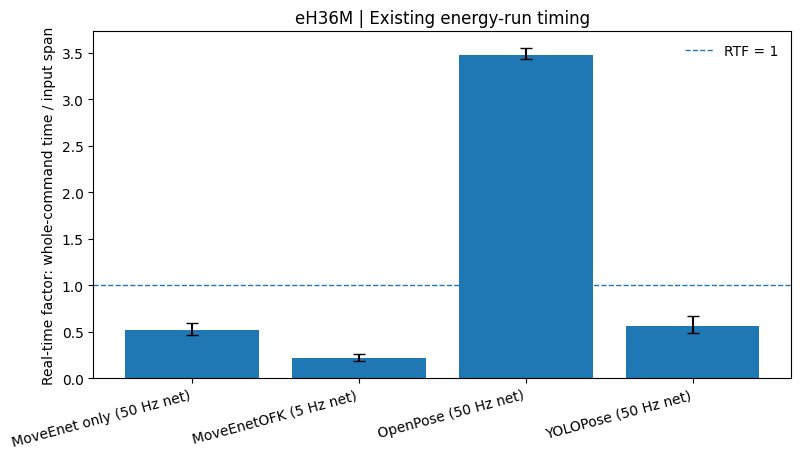

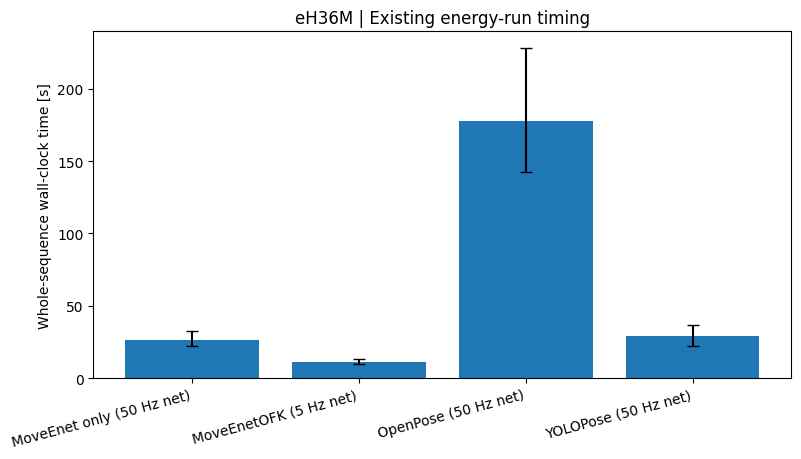

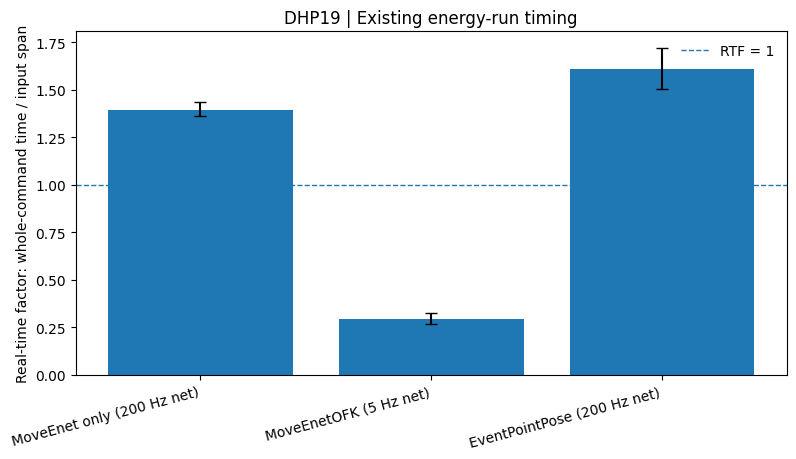

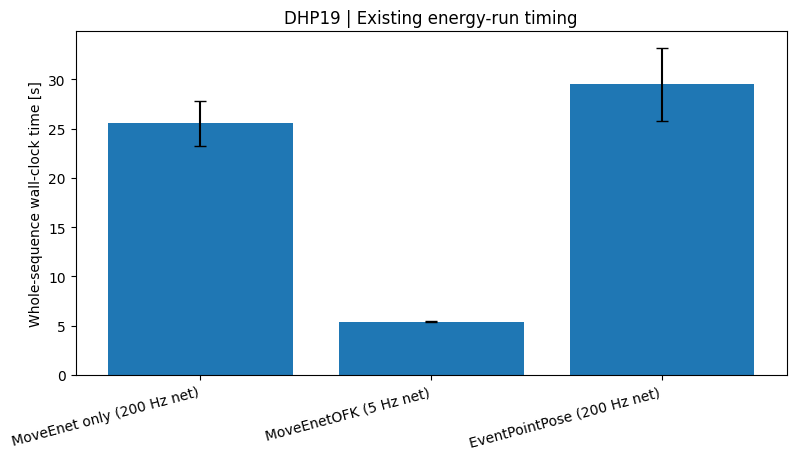

In [4]:
for dataset in ("h36m", "dhp19"):
    for metric in ("real_time_factor", "wall_mean_s"):
        figure = plot_runtime(summary_runtime, dataset, metric)
        display(figure)
        figure.savefig(FIGURES / f"{dataset}_{metric}{FINAL_FIGURE_SUFFIX}.png",
                       dpi=300, bbox_inches="tight")
        figure.savefig(FIGURES / f"{dataset}_{metric}{FINAL_FIGURE_SUFFIX}.svg",
                       bbox_inches="tight")
        plt.close(figure)


## Normalizzazioni a 5, 20, 50, 100 e 200 slot/s

Sono divisioni dello **stesso costo misurato**, non nuovi risultati sperimentali a frequenze diverse. Nel confronto principale tutti i metodi hanno output nominale 200 Hz.

In [5]:
normalizations_all = pd.read_csv(TABLES / "amortized_time_normalizations.csv")
normalizations = apply_sample_exclusions(normalizations_all)
normalizations.to_csv(TABLES / "amortized_time_normalizations_valid_subset.csv", index=False)

display(normalizations.pivot_table(index=["dataset", "sample_id", "model", "measured_net_hz"],
                                  columns="normalization_frequency_hz", values="amortized_ms").head(14))
print("Subset finale:", TABLES / "amortized_time_normalizations_valid_subset.csv")


normalization_frequency_hz                               5          20   \
dataset sample_id model          measured_net_hz                          
dhp19   D01       eventpointpose 200.0            276.126227  69.031557   
                  moveenetofk    5.0               47.556317  11.889079   
                  movenet        200.0            264.220572  66.055143   
        D02       eventpointpose 200.0            329.891609  82.472902   
                  moveenetofk    5.0               71.266499  17.816625   
                  movenet        200.0            297.050637  74.262659   
        D03       eventpointpose 200.0            327.116914  81.779228   
                  moveenetofk    5.0               62.035999  15.509000   
                  movenet        200.0            284.392546  71.098137   
        D04       eventpointpose 200.0            351.568783  87.892196   
                  moveenetofk    5.0               52.228082  13.057020   
                  movenet        200.0            271.572466  67.893117   
        D05       eventpointpose 200.0            381.340066  95.335016   
                  moveenetofk    5.0               52.419424  13.104856   

normalization_frequency_hz                              50         100  \
dataset sample_id model          measured_net_hz                         
dhp19   D01       eventpointpose 200.0            27.612623  13.806311   
                  moveenetofk    5.0               4.755632   2.377816   
                  movenet        200.0            26.422057  13.211029   
        D02       eventpointpose 200.0            32.989161  16.494580   
                  moveenetofk    5.0               7.126650   3.563325   
                  movenet        200.0            29.705064  14.852532   
        D03       eventpointpose 200.0            32.711691  16.355846   
                  moveenetofk    5.0               6.203600   3.101800   
                  movenet        200.0            28.439255  14.219627   
        D04       eventpointpose 200.0            35.156878  17.578439   
                  moveenetofk    5.0               5.222808   2.611404   
                  movenet        200.0            27.157247  13.578623   
        D05       eventpointpose 200.0            38.134007  19.067003   
                  moveenetofk    5.0               5.241942   2.620971   

normalization_frequency_hz                             200  
dataset sample_id model          measured_net_hz            
dhp19   D01       eventpointpose 200.0            6.903156  
                  moveenetofk    5.0              1.188908  
                  movenet        200.0            6.605514  
        D02       eventpointpose 200.0            8.247290  
                  moveenetofk    5.0              1.781662  
                  movenet        200.0            7.426266  
        D03       eventpointpose 200.0            8.177923  
                  moveenetofk    5.0              1.550900  
                  movenet        200.0            7.109814  
        D04       eventpointpose 200.0            8.789220  
                  moveenetofk    5.0              1.305702  
                  movenet        200.0            6.789312  
        D05       eventpointpose 200.0            9.533502  
                  moveenetofk    5.0              1.310486

Subset finale: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/tables/amortized_time_normalizations_valid_subset.csv


## Provenienza della durata

Per gli eventi si usa l'intervallo tra primo e ultimo timestamp riportato dal loader nel log energetico. Per il video si leggono i timestamp del primo e ultimo frame con OpenCV; il fallback `(frame_count-1)/fps`, quando necessario, viene etichettato esplicitamente. La durata non e' dedotta dal numero di pose valide, che dipende dal metodo.

In [6]:
display(runtime.groupby(["dataset", "model", "duration_source"]).agg(
    samples=("sample_id", "nunique"),
    minimum_input_span_s=("input_span_s", "min"),
    maximum_input_span_s=("input_span_s", "max")))
print("Non sostituire sequence_wall_seconds con accuracy_replay_wall_seconds.")


samples  \
dataset model          duration_source                                               
dhp19   eventpointpose energy_log_loader_last_minus_first_packet_times...       10   
        moveenetofk    energy_log_loader_last_minus_first_packet_times...       10   
        movenet        energy_log_loader_last_minus_first_packet_times...       10   
h36m    moveenetofk    energy_log_loader_last_minus_first_packet_times...       12   
        movenet        energy_log_loader_last_minus_first_packet_times...       12   
        openpose       OpenCV_last_minus_first_frame_timestamp                  12   
        yolo           OpenCV_last_minus_first_frame_timestamp                  12   

                                                                           minimum_input_span_s  \
dataset model          duration_source                                                            
dhp19   eventpointpose energy_log_loader_last_minus_first_packet_times...               13.8952   
        moveenetofk    energy_log_loader_last_minus_first_packet_times...               13.8952   
        movenet        energy_log_loader_last_minus_first_packet_times...               13.8952   
h36m    moveenetofk    energy_log_loader_last_minus_first_packet_times...               23.7860   
        movenet        energy_log_loader_last_minus_first_packet_times...               23.7860   
        openpose       OpenCV_last_minus_first_frame_timestamp                          23.7200   
        yolo           OpenCV_last_minus_first_frame_timestamp                          23.7200   

                                                                           maximum_input_span_s  
dataset model          duration_source                                                           
dhp19   eventpointpose energy_log_loader_last_minus_first_packet_times...               23.4197  
        moveenetofk    energy_log_loader_last_minus_first_packet_times...               23.4197  
        movenet        energy_log_loader_last_minus_first_packet_times...               23.4197  
h36m    moveenetofk    energy_log_loader_last_minus_first_packet_times...              117.5470  
        movenet        energy_log_loader_last_minus_first_packet_times...              117.5470  
        openpose       OpenCV_last_minus_first_frame_timestamp                         117.4400  
        yolo           OpenCV_last_minus_first_frame_timestamp                         117.4400

Non sostituire sequence_wall_seconds con accuracy_replay_wall_seconds.
